# LAB 2 – Bài 1: Phân loại chữ số MNIST bằng LeNet

## Phiên bản dành cho sinh viên mới học PyTorch

Notebook này hướng dẫn xây dựng một mạng CNN kiểu **LeNet** để phân loại ảnh chữ số viết tay từ 0 đến 9.

### Mục tiêu học tập

Sau khi hoàn thành bài, sinh viên có thể:

1. Giải thích vai trò của tập train, validation và test.
2. Đọc dữ liệu MNIST từ các file IDX.
3. Xây dựng `Dataset` và `DataLoader`.
4. Hiểu kích thước tensor đi qua từng lớp convolution.
5. Xây dựng mô hình LeNet bằng `nn.Module`.
6. Viết vòng lặp huấn luyện đúng chuẩn PyTorch.
7. Lưu và tải lại checkpoint tốt nhất.
8. Đánh giá mô hình bằng accuracy, precision, recall và macro F1.
9. Phân tích confusion matrix và các ảnh dự đoán sai.

> **Nguyên tắc quan trọng:**  
> Tập test chỉ được sử dụng sau khi đã hoàn tất việc huấn luyện và lựa chọn mô hình.

## 1. Cấu trúc thư mục

Đặt notebook cùng cấp với thư mục dữ liệu:

```text
LAB2_Bai1_LeNet.ipynb
mnist-dataset/
├── train-images-idx3-ubyte
├── train-labels-idx1-ubyte
├── t10k-images-idx3-ubyte
└── t10k-labels-idx1-ubyte
```

Notebook cũng thử tìm dữ liệu ở một số đường dẫn thường gặp. Nếu vẫn không tìm thấy, chương trình sẽ báo rõ các file còn thiếu.

## 2. Cài đặt thư viện

Chỉ chạy lệnh dưới đây khi môi trường chưa có thư viện cần thiết.

```python
%pip install torch numpy matplotlib scikit-learn idx2numpy
```

Không nên chạy lại lệnh cài đặt ở mọi lần mở notebook nếu các thư viện đã tồn tại.

In [1]:
# Có thể bỏ dấu # ở dòng dưới nếu cần cài thư viện.
%pip install torch numpy matplotlib scikit-learn idx2numpy

Note: you may need to restart the kernel to use updated packages.


## 3. Import thư viện và cấu hình thí nghiệm

### Vì sao phải đặt random seed?

Trong quá trình huấn luyện có nhiều yếu tố ngẫu nhiên:

- Trọng số ban đầu của mô hình.
- Thứ tự dữ liệu sau khi `shuffle`.
- Một số phép toán trên GPU.

Đặt seed giúp kết quả giữa các lần chạy gần giống nhau hơn và làm thí nghiệm dễ kiểm chứng.

In [3]:
import json
import random
from pathlib import Path

import idx2numpy
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import (
    ConfusionMatrixDisplay,  # Hiển thị ma trận nhầm lẫn dưới dạng biểu đồ
    accuracy_score,          # Tính độ chính xác tổng thể của mô hình
    classification_report,   # Tạo báo cáo gồm precision, recall, F1-score và support
    confusion_matrix,        # Tạo ma trận nhầm lẫn giữa nhãn thật và nhãn dự đoán
    f1_score,                # Tính điểm F1, cân bằng giữa precision và recall
    precision_score,         # Tính precision: tỷ lệ dự đoán dương tính đúng
    recall_score,            # Tính recall: tỷ lệ mẫu dương tính được dự đoán đúng
)
from torch.utils.data import DataLoader, Dataset, random_split


SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Thiết bị đang sử dụng:", device)
print("Phiên bản PyTorch:", torch.__version__)

Thiết bị đang sử dụng: cpu
Phiên bản PyTorch: 2.12.0+cpu


## 4. Cấu hình chung

Các siêu tham số được đặt chung tại một vị trí để dễ thay đổi và so sánh thí nghiệm.

### Lựa chọn ban đầu

- `batch_size = 64`: đủ nhỏ để chạy trên nhiều máy, nhưng vẫn tận dụng tính toán theo batch.
- `learning_rate = 0.001`: mức khởi đầu phổ biến cho Adam.
- `epochs = 15`: chỉ là giới hạn tối đa; early stopping có thể dừng sớm hơn.
- `validation_ratio = 0.1`: dùng 10% dữ liệu train để lựa chọn mô hình.

In [5]:
BATCH_SIZE = 64                   # Số lượng ảnh được xử lý trong mỗi batch
LEARNING_RATE = 1e-3              # Tốc độ học của mô hình, tương đương 0.001
MAX_EPOCHS = 15                   # Số epoch tối đa để huấn luyện mô hình
VALIDATION_RATIO = 0.10           # Dùng 10% dữ liệu huấn luyện để làm tập validation
EARLY_STOPPING_PATIENCE = 3       # Dừng nếu validation không cải thiện sau 3 epoch liên tiếp

CHECKPOINT_PATH = Path("best_lenet_mnist.pth")          # Đường dẫn lưu trọng số của mô hình tốt nhất
HISTORY_PATH = Path("lenet_training_history.json")      # Đường dẫn lưu lịch sử huấn luyện

## 5. Tìm thư mục dữ liệu

Không nên viết cứng một đường dẫn chỉ đúng trên máy cá nhân.  
Đoạn code dưới đây thử một số vị trí thường gặp và kiểm tra đủ bốn file MNIST.

In [6]:
REQUIRED_FILES = [
    "train-images-idx3-ubyte",
    "train-labels-idx1-ubyte",
    "t10k-images-idx3-ubyte",
    "t10k-labels-idx1-ubyte",
]

candidate_directories = [
    Path("./mnist-dataset"),
    Path("../mnist-dataset"),
    Path("../../LAB1/mnist-dataset"),
]

data_dir = None

for candidate in candidate_directories:
    if all((candidate / filename).exists() for filename in REQUIRED_FILES):
        data_dir = candidate
        break

if data_dir is None:
    searched = "\n".join(f"- {path.resolve()}" for path in candidate_directories)
    raise FileNotFoundError(
        "Không tìm thấy đầy đủ dữ liệu MNIST.\n"
        "Đã kiểm tra các thư mục:\n"
        f"{searched}\n\n"
        "Hãy đặt thư mục 'mnist-dataset' cùng cấp với notebook "
        "hoặc sửa danh sách candidate_directories."
    )

print("Đã tìm thấy dữ liệu tại:", data_dir.resolve())

Đã tìm thấy dữ liệu tại: C:\Users\Admin\Desktop\UIT-2025\HocTap\DS\DS201_DL_FOR_DS\Deep-Learning-trong-Khoa-hoc-du-lieu-main\LAB1\mnist-dataset


# Phần A – Dữ liệu

## 6. Tại sao cần `Dataset` và `DataLoader`?

### `Dataset`

`Dataset` định nghĩa:

- Có bao nhiêu mẫu dữ liệu.
- Khi yêu cầu mẫu thứ `i`, chương trình phải trả về ảnh và nhãn nào.

### `DataLoader`

`DataLoader` hỗ trợ:

- Ghép nhiều mẫu thành một batch.
- Trộn dữ liệu train bằng `shuffle=True`.
- Duyệt dữ liệu thuận tiện trong vòng lặp huấn luyện.

Trong phiên bản này, `Dataset` trả về **Tensor trực tiếp**. Vì vậy, không cần viết `collate_fn` thủ công.

In [8]:
class MnistIdxDataset(Dataset):
    """Đọc ảnh và nhãn MNIST từ định dạng IDX."""

    def __init__(self, image_path, label_path):
        images_np = idx2numpy.convert_from_file(str(image_path))
        labels_np = idx2numpy.convert_from_file(str(label_path))

        if len(images_np) != len(labels_np):
            raise ValueError(
                f"Số ảnh ({len(images_np)}) khác số nhãn ({len(labels_np)})."
            )

        # Giữ ảnh ở uint8 để tiết kiệm bộ nhớ.
        # Mỗi ảnh sẽ được chuyển sang float và chuẩn hóa khi lấy ra.
        self.images = torch.from_numpy(images_np).unsqueeze(1)
        self.labels = torch.from_numpy(labels_np.astype(np.int64))

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        image = self.images[index].float() / 255.0
        label = self.labels[index]

        return {
            "image": image,
            "label": label,
        }

## 7. Vì sao chia pixel cho 255?

Ảnh gốc có giá trị pixel từ 0 đến 255.

Sau phép biến đổi:

```python
image.float() / 255.0
```

giá trị pixel nằm trong khoảng `[0, 1]`.

Việc này giúp:

- Các giá trị đầu vào có quy mô nhỏ và ổn định.
- Quá trình tối ưu thường dễ hơn.
- Tránh để các giá trị pixel lớn làm gradient dao động mạnh.

Đây là **scale về [0, 1]**, chưa phải chuẩn hóa theo mean và standard deviation.

In [9]:
full_train_dataset = MnistIdxDataset(
    image_path=data_dir / "train-images-idx3-ubyte",
    label_path=data_dir / "train-labels-idx1-ubyte",
)

test_dataset = MnistIdxDataset(
    image_path=data_dir / "t10k-images-idx3-ubyte",
    label_path=data_dir / "t10k-labels-idx1-ubyte",
)

print("Tổng số mẫu train ban đầu:", len(full_train_dataset))
print("Tổng số mẫu test:", len(test_dataset))
print("Kích thước một ảnh:", full_train_dataset[0]["image"].shape)
print("Nhãn mẫu đầu tiên:", full_train_dataset[0]["label"].item())

Tổng số mẫu train ban đầu: 60000
Tổng số mẫu test: 10000
Kích thước một ảnh: torch.Size([1, 28, 28])
Nhãn mẫu đầu tiên: 5


C:\Users\Admin\AppData\Local\Temp\ipykernel_32824\1437689011.py:15: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  self.images = torch.from_numpy(images_np).unsqueeze(1)


## 8. Chia train, validation và test

### Train set

Dùng để tính loss, lan truyền ngược và cập nhật trọng số.

### Validation set

Dùng để:

- Theo dõi chất lượng sau mỗi epoch.
- Chọn checkpoint tốt nhất.
- Quyết định khi nào dừng sớm.
- So sánh learning rate hoặc kiến trúc.

### Test set

Chỉ dùng **một lần ở cuối**, sau khi mọi lựa chọn đã hoàn tất.

Nếu dùng test sau mỗi epoch để chọn mô hình, kết quả test không còn hoàn toàn khách quan.

In [10]:
validation_size = int(len(full_train_dataset) * VALIDATION_RATIO)
train_size = len(full_train_dataset) - validation_size

split_generator = torch.Generator().manual_seed(SEED)

train_dataset, validation_dataset = random_split(
    full_train_dataset,
    lengths=[train_size, validation_size],
    generator=split_generator,
)

print("Số mẫu train:", len(train_dataset))
print("Số mẫu validation:", len(validation_dataset))
print("Số mẫu test:", len(test_dataset))

Số mẫu train: 54000
Số mẫu validation: 6000
Số mẫu test: 10000


## 9. Tạo DataLoader

- Train dùng `shuffle=True` vì không muốn mô hình luôn nhìn dữ liệu theo cùng một thứ tự.
- Validation và test dùng `shuffle=False` vì không cập nhật trọng số.
- `num_workers=0` có tính tương thích cao trong Jupyter và Windows.
- `pin_memory=True` có thể hỗ trợ truyền dữ liệu sang GPU nhanh hơn.

In [11]:
loader_generator = torch.Generator().manual_seed(SEED)
pin_memory = device.type == "cuda"

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=pin_memory,
    generator=loader_generator,
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=pin_memory,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=pin_memory,
)

first_batch = next(iter(train_loader))

print("Batch ảnh:", first_batch["image"].shape)
print("Batch nhãn:", first_batch["label"].shape)
print("Kiểu dữ liệu ảnh:", first_batch["image"].dtype)
print(
    "Khoảng giá trị pixel:",
    first_batch["image"].min().item(),
    "đến",
    first_batch["image"].max().item(),
)

Batch ảnh: torch.Size([64, 1, 28, 28])
Batch nhãn: torch.Size([64])
Kiểu dữ liệu ảnh: torch.float32
Khoảng giá trị pixel: 0.0 đến 1.0


## 10. Hiển thị một số ảnh mẫu

Luôn nên xem trực tiếp dữ liệu trước khi huấn luyện để phát hiện:

- Ảnh bị đảo chiều.
- Sai kích thước.
- Nhãn không khớp.
- Giá trị pixel bất thường.

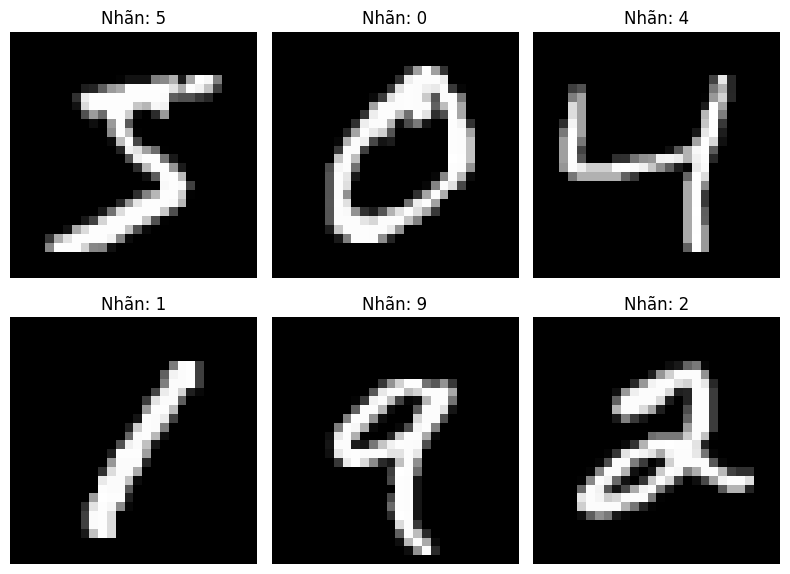

In [12]:
sample_indices = [0, 1, 2, 3, 4, 5]

fig, axes = plt.subplots(2, 3, figsize=(8, 6))

for axis, index in zip(axes.flat, sample_indices):
    sample = full_train_dataset[index]
    axis.imshow(sample["image"].squeeze(0), cmap="gray")
    axis.set_title(f"Nhãn: {sample['label'].item()}")
    axis.axis("off")

plt.tight_layout()
plt.show()

# Phần B – Mô hình LeNet

## 11. Convolution học gì?

Một lớp convolution dùng các kernel nhỏ quét trên ảnh để học đặc trưng như:

- Cạnh ngang và cạnh dọc.
- Nét cong.
- Góc.
- Cấu trúc phức tạp hơn ở các lớp sâu.

Khác với mạng fully connected, convolution tận dụng quan hệ không gian giữa các pixel và dùng chung trọng số trên toàn ảnh.

## 12. Công thức tính kích thước đầu ra convolution

Với một chiều không gian:

\[
	ext{output}
=
\left\lfloor

rac{W + 2P - K}{S}

ight
floor + 1
\]

Trong đó:

- \(W\): kích thước đầu vào.
- \(K\): kernel size.
- \(P\): padding.
- \(S\): stride.

Kiến trúc trong bài:

```text
Input:            1 × 28 × 28
Conv1:            6 × 28 × 28
AvgPool1:         6 × 14 × 14
Conv2:           16 × 10 × 10
AvgPool2:        16 ×  5 ×  5
Conv3:          120 ×  1 ×  1
Flatten:        120
Linear:          84
Output:          10 logits
```

Đây là một phiên bản **LeNet-style được điều chỉnh cho ảnh MNIST 28×28**.

In [15]:
class LeNetForMNIST(nn.Module):  # Định nghĩa mô hình LeNet dùng để phân loại ảnh MNIST
    def __init__(self, num_classes=10):  # num_classes=10 vì MNIST có 10 chữ số từ 0 đến 9
        super().__init__()  # Khởi tạo lớp cha nn.Module

        # Phần trích xuất đặc trưng từ ảnh
        self.features = nn.Sequential(

            # Ảnh đầu vào: [batch_size, 1, 28, 28]
            nn.Conv2d(
                in_channels=1,   # Ảnh MNIST là ảnh xám nên chỉ có 1 kênh
                out_channels=6,  # Sử dụng 6 bộ lọc để tạo ra 6 feature map
                kernel_size=5,   # Kích thước bộ lọc là 5×5
                stride=1,        # Bộ lọc di chuyển mỗi lần 1 pixel
                padding=2,       # Thêm 2 pixel xung quanh để giữ kích thước 28×28
            ),                   # Đầu ra: [batch_size, 6, 28, 28]

            nn.ReLU(),  # Thêm tính phi tuyến, biến các giá trị âm thành 0

            nn.AvgPool2d(
                kernel_size=2,  # Vùng lấy trung bình có kích thước 2×2
                stride=2,       # Di chuyển 2 pixel, giúp giảm một nửa kích thước ảnh
            ),                  # Đầu ra: [batch_size, 6, 14, 14]

            nn.Conv2d(
                in_channels=6,   # Nhận 6 feature map từ lớp trước
                out_channels=16, # Tạo ra 16 feature map mới
                kernel_size=5,   # Bộ lọc có kích thước 5×5
                stride=1,        # Bộ lọc di chuyển mỗi lần 1 pixel
                padding=0,       # Không thêm pixel xung quanh
            ),                   # Đầu ra: [batch_size, 16, 10, 10]

            nn.ReLU(),  # Hàm kích hoạt ReLU

            nn.AvgPool2d(
                kernel_size=2,  # Lấy giá trị trung bình trong vùng 2×2
                stride=2,       # Giảm kích thước chiều cao và chiều rộng một nửa
            ),                  # Đầu ra: [batch_size, 16, 5, 5]

            nn.Conv2d(
                in_channels=16,   # Nhận 16 feature map từ lớp trước
                out_channels=120, # Tạo ra 120 feature map
                kernel_size=5,    # Bộ lọc 5×5 phủ toàn bộ feature map 5×5
                stride=1,         # Di chuyển mỗi lần 1 pixel
                padding=0,        # Không thêm padding
            ),                    # Đầu ra: [batch_size, 120, 1, 1]

            nn.ReLU(),  # Hàm kích hoạt ReLU
        )

        # Phần phân loại ảnh dựa trên các đặc trưng đã trích xuất
        self.classifier = nn.Sequential(
            nn.Flatten(),               # Chuyển [batch_size, 120, 1, 1] thành [batch_size, 120]
            nn.Linear(120, 84),          # Lớp kết nối đầy đủ: 120 đầu vào → 84 đầu ra
            nn.ReLU(),                   # Hàm kích hoạt ReLU
            nn.Linear(84, num_classes),  # Tạo điểm dự đoán cho 10 lớp từ 0 đến 9
        )

    def forward(self, images):  # Quy định quá trình dữ liệu đi qua mô hình
        features = self.features(images)      # Trích xuất đặc trưng từ ảnh
        logits = self.classifier(features)    # Phân loại dựa trên đặc trưng
        return logits                         # Trả về điểm dự đoán của từng lớp

## 13. Vì sao đầu ra là logits, không phải Softmax?

Mô hình trả về 10 giá trị chưa chuẩn hóa gọi là **logits**.

Ta sử dụng:

```python
nn.CrossEntropyLoss()
```

Hàm loss này đã kết hợp phép toán tương đương `LogSoftmax` và `NLLLoss` theo cách ổn định số học.

Vì vậy, không nên thêm:

```python
F.softmax(...)
```

hoặc:

```python
F.log_softmax(...)
```

vào `forward()` khi huấn luyện bằng `CrossEntropyLoss`.

In [ ]:
model = LeNetForMNIST(num_classes=10).to(device)
# Khởi tạo mô hình LeNet với 10 lớp tương ứng các chữ số từ 0 đến 9
# .to(device) chuyển mô hình sang CPU hoặc GPU

total_parameters = sum(
    parameter.numel()             # Đếm tổng số phần tử trong mỗi tensor tham số
    for parameter in model.parameters()  # Duyệt qua toàn bộ tham số của mô hình
    if parameter.requires_grad    # Chỉ đếm những tham số được cập nhật khi huấn luyện
)

print(model)  # In cấu trúc các lớp của mô hình

print(f"\nSố tham số có thể học: {total_parameters:,}")
# In tổng số tham số có thể học
# Dấu :, giúp định dạng số có dấu phân cách hàng nghìn

LeNetForMNIST(
  (features): Sequential(
    (0): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): ReLU()
    (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): ReLU()
    (5): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (6): Conv2d(16, 120, kernel_size=(5, 5), stride=(1, 1))
    (7): ReLU()
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=120, out_features=84, bias=True)
    (2): ReLU()
    (3): Linear(in_features=84, out_features=10, bias=True)
  )
)

Số tham số có thể học: 61,706


## 14. Kiểm tra đầu ra trước khi huấn luyện

Đây là bước sanity check quan trọng.

Với batch có dạng:

```text
(batch_size, 1, 28, 28)
```

đầu ra phải có dạng:

```text
(batch_size, 10)
```

Mỗi hàng chứa 10 logits tương ứng 10 lớp chữ số.

In [17]:
with torch.no_grad():
    dummy_images = torch.randn(4, 1, 28, 28, device=device)
    dummy_logits = model(dummy_images)

print("Input shape:", dummy_images.shape)
print("Output shape:", dummy_logits.shape)

assert dummy_logits.shape == (4, 10)

Input shape: torch.Size([4, 1, 28, 28])
Output shape: torch.Size([4, 10])


## 15. Theo dõi kích thước tensor qua từng khối

Đoạn code dưới đây giúp sinh viên kiểm chứng các phép tính kích thước thay vì chỉ học thuộc kiến trúc.

In [18]:
def print_feature_shapes(model, images):
    x = images

    print("Input:   ", tuple(x.shape))

    for index, layer in enumerate(model.features):
        x = layer(x)
        print(f"{index:02d} {layer.__class__.__name__:12s}", tuple(x.shape))

    x = model.classifier(x)
    print("Logits:  ", tuple(x.shape))


sample_images = first_batch["image"][:4].to(device)
print_feature_shapes(model, sample_images)

Input:    (4, 1, 28, 28)
00 Conv2d       (4, 6, 28, 28)
01 ReLU         (4, 6, 28, 28)
02 AvgPool2d    (4, 6, 14, 14)
03 Conv2d       (4, 16, 10, 10)
04 ReLU         (4, 16, 10, 10)
05 AvgPool2d    (4, 16, 5, 5)
06 Conv2d       (4, 120, 1, 1)
07 ReLU         (4, 120, 1, 1)
Logits:   (4, 10)


In [19]:
del sample_images
if device.type == "cuda":
    torch.cuda.empty_cache()

# Phần C – Loss, optimizer và chỉ số đánh giá

## 16. Cross-entropy loss

Với bài toán phân loại nhiều lớp, cross-entropy phạt mô hình khi:

- Logit của lớp đúng quá thấp.
- Mô hình quá tự tin vào lớp sai.

Mục tiêu huấn luyện là làm loss giảm dần trên train set nhưng đồng thời chất lượng trên validation set phải được cải thiện.

## 17. Tại sao chọn Adam với learning rate 0.001?

Adam tự điều chỉnh mức cập nhật cho từng tham số và thường dễ dùng cho người mới.

`0.001` là mức khởi đầu phổ biến. Tuy nhiên, đây không phải giá trị đúng cho mọi bài toán.

- Learning rate quá lớn: loss có thể dao động hoặc không hội tụ.
- Learning rate quá nhỏ: mô hình học rất chậm.

Việc chọn learning rate phải dựa trên validation set, không dựa trên test set.

In [20]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
)

print(loss_fn)
print(optimizer)

CrossEntropyLoss()
Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


## 18. Các chỉ số đánh giá

### Accuracy

Tỷ lệ dự đoán đúng trên toàn bộ mẫu.

### Precision

Trong các mẫu được dự đoán là một lớp, có bao nhiêu mẫu thật sự thuộc lớp đó?

### Recall

Trong các mẫu thật sự thuộc một lớp, mô hình tìm đúng được bao nhiêu?

### F1-score

Trung bình điều hòa của precision và recall.

### Vì sao dùng macro average?

Macro average tính chỉ số riêng cho từng lớp rồi lấy trung bình.  
Mỗi lớp có trọng số ngang nhau, kể cả khi số lượng mẫu giữa các lớp khác nhau.

In [21]:
def evaluate_model(model, dataloader, loss_fn, return_predictions=False):
    model.eval()

    total_loss = 0.0
    total_samples = 0
    all_predictions = []
    all_labels = []

    with torch.no_grad():
        for batch in dataloader:
            images = batch["image"].to(device, non_blocking=True)
            labels = batch["label"].to(device, non_blocking=True)

            logits = model(images)
            loss = loss_fn(logits, labels)

            batch_size = images.size(0)
            total_loss += loss.item() * batch_size
            total_samples += batch_size

            predictions = logits.argmax(dim=1)

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    y_true = np.asarray(all_labels)
    y_pred = np.asarray(all_predictions)

    metrics = {
        "loss": total_loss / total_samples,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0,
        ),
        "recall_macro": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0,
        ),
        "f1_macro": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0,
        ),
    }

    if return_predictions:
        metrics["y_true"] = y_true
        metrics["y_pred"] = y_pred

    return metrics

# Phần D – Huấn luyện đúng quy trình

## 19. Hàm huấn luyện một epoch

Trong mỗi batch, thứ tự chuẩn là:

1. Chuyển dữ liệu sang thiết bị.
2. Xóa gradient cũ.
3. Forward để tính logits.
4. Tính loss.
5. Backward để tính gradient.
6. Optimizer cập nhật trọng số.

### Vì sao phải `zero_grad()`?

PyTorch mặc định cộng dồn gradient. Nếu không xóa gradient cũ, gradient của nhiều batch sẽ bị cộng lại ngoài ý muốn.

In [22]:
def train_one_epoch(model, dataloader, loss_fn, optimizer):
    model.train()

    total_loss = 0.0
    total_samples = 0

    for batch in dataloader:
        images = batch["image"].to(device, non_blocking=True)
        labels = batch["label"].to(device, non_blocking=True)

        optimizer.zero_grad()

        logits = model(images)
        loss = loss_fn(logits, labels)

        loss.backward()
        optimizer.step()

        batch_size = images.size(0)
        total_loss += loss.item() * batch_size
        total_samples += batch_size

    return total_loss / total_samples

## 20. Checkpoint và early stopping

### Checkpoint tốt nhất

Sau mỗi epoch, ta đánh giá trên validation set.  
Nếu macro F1 tốt hơn trước, mô hình được lưu lại.

### Early stopping

Nếu validation F1 không cải thiện trong một số epoch liên tiếp, quá trình huấn luyện dừng sớm.

Lợi ích:

- Tiết kiệm thời gian.
- Giảm nguy cơ overfitting.
- Không cần giả định epoch cuối luôn là epoch tốt nhất.

> Tập test không xuất hiện trong vòng lặp dưới đây.

In [23]:
history = {
    "train_loss": [],
    "validation_loss": [],
    "validation_accuracy": [],
    "validation_f1_macro": [],
}

best_validation_f1 = float("-inf")
epochs_without_improvement = 0

for epoch in range(1, MAX_EPOCHS + 1):
    train_loss = train_one_epoch(
        model=model,
        dataloader=train_loader,
        loss_fn=loss_fn,
        optimizer=optimizer,
    )

    validation_metrics = evaluate_model(
        model=model,
        dataloader=validation_loader,
        loss_fn=loss_fn,
    )

    history["train_loss"].append(train_loss)
    history["validation_loss"].append(validation_metrics["loss"])
    history["validation_accuracy"].append(validation_metrics["accuracy"])
    history["validation_f1_macro"].append(validation_metrics["f1_macro"])

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {validation_metrics['loss']:.4f} | "
        f"Val accuracy: {validation_metrics['accuracy']:.4f} | "
        f"Val macro F1: {validation_metrics['f1_macro']:.4f}"
    )

    if validation_metrics["f1_macro"] > best_validation_f1:
        best_validation_f1 = validation_metrics["f1_macro"]
        epochs_without_improvement = 0

        checkpoint = {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "validation_metrics": validation_metrics,
            "config": {
                "batch_size": BATCH_SIZE,
                "learning_rate": LEARNING_RATE,
                "max_epochs": MAX_EPOCHS,
                "validation_ratio": VALIDATION_RATIO,
                "seed": SEED,
            },
        }

        torch.save(checkpoint, CHECKPOINT_PATH)

        print(
            "  -> Đã lưu checkpoint mới, "
            f"validation macro F1 = {best_validation_f1:.4f}"
        )
    else:
        epochs_without_improvement += 1
        print(
            "  -> Chưa cải thiện. "
            f"Early stopping counter: "
            f"{epochs_without_improvement}/{EARLY_STOPPING_PATIENCE}"
        )

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print("\nDừng sớm vì validation F1 không còn cải thiện.")
        break

with HISTORY_PATH.open("w", encoding="utf-8") as file:
    json.dump(history, file, indent=2)

print("\nĐã lưu lịch sử huấn luyện tại:", HISTORY_PATH.resolve())
print("Checkpoint tốt nhất tại:", CHECKPOINT_PATH.resolve())

Epoch 01/15 | Train loss: 0.3505 | Val loss: 0.1457 | Val accuracy: 0.9560 | Val macro F1: 0.9556
  -> Đã lưu checkpoint mới, validation macro F1 = 0.9556
Epoch 02/15 | Train loss: 0.1017 | Val loss: 0.0845 | Val accuracy: 0.9747 | Val macro F1: 0.9744
  -> Đã lưu checkpoint mới, validation macro F1 = 0.9744
Epoch 03/15 | Train loss: 0.0742 | Val loss: 0.0823 | Val accuracy: 0.9738 | Val macro F1: 0.9735
  -> Chưa cải thiện. Early stopping counter: 1/3
Epoch 04/15 | Train loss: 0.0575 | Val loss: 0.0608 | Val accuracy: 0.9830 | Val macro F1: 0.9828
  -> Đã lưu checkpoint mới, validation macro F1 = 0.9828
Epoch 05/15 | Train loss: 0.0477 | Val loss: 0.0536 | Val accuracy: 0.9845 | Val macro F1: 0.9843
  -> Đã lưu checkpoint mới, validation macro F1 = 0.9843
Epoch 06/15 | Train loss: 0.0400 | Val loss: 0.0444 | Val accuracy: 0.9850 | Val macro F1: 0.9847
  -> Đã lưu checkpoint mới, validation macro F1 = 0.9847
Epoch 07/15 | Train loss: 0.0335 | Val loss: 0.0471 | Val accuracy: 0.9872 | V

## 21. Vẽ lịch sử huấn luyện

Ta quan sát đồng thời:

- Train loss.
- Validation loss.
- Validation accuracy.
- Validation macro F1.

Dấu hiệu overfitting thường gặp:

- Train loss tiếp tục giảm.
- Validation loss bắt đầu tăng.
- Validation accuracy hoặc F1 không còn cải thiện.

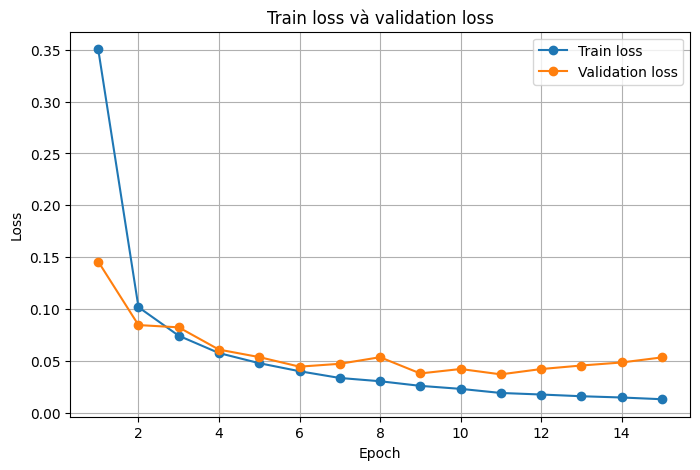

In [24]:
epochs_ran = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs_ran, history["train_loss"], marker="o", label="Train loss")
plt.plot(
    epochs_ran,
    history["validation_loss"],
    marker="o",
    label="Validation loss",
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Train loss và validation loss")
plt.grid(True)
plt.legend()
plt.show()

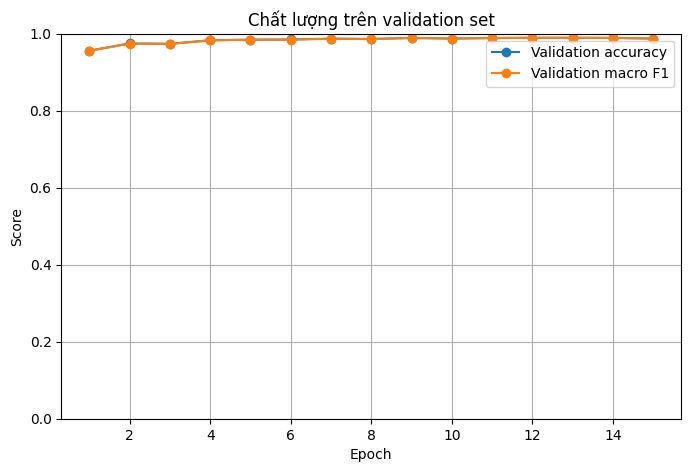

In [25]:
plt.figure(figsize=(8, 5))
plt.plot(
    epochs_ran,
    history["validation_accuracy"],
    marker="o",
    label="Validation accuracy",
)
plt.plot(
    epochs_ran,
    history["validation_f1_macro"],
    marker="o",
    label="Validation macro F1",
)
plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Chất lượng trên validation set")
plt.ylim(0, 1)
plt.grid(True)
plt.legend()
plt.show()

# Phần E – Đánh giá cuối cùng trên test set

## 22. Tải lại checkpoint tốt nhất

Không nên đánh giá trực tiếp mô hình ở epoch cuối vì epoch cuối chưa chắc tốt nhất.

Ta tải lại checkpoint đã được lựa chọn dựa trên validation macro F1.

In [26]:
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
)

model.load_state_dict(checkpoint["model_state_dict"])

print("Đã tải checkpoint từ epoch:", checkpoint["epoch"])
print(
    "Validation macro F1 tốt nhất:",
    f"{checkpoint['validation_metrics']['f1_macro']:.4f}",
)

Đã tải checkpoint từ epoch: 13
Validation macro F1 tốt nhất: 0.9894


## 23. Chỉ bây giờ mới sử dụng test set

Kết quả test dưới đây là ước lượng cuối cùng về khả năng tổng quát của mô hình.

Không dùng kết quả này để:

- Chọn epoch khác.
- Thay learning rate rồi tiếp tục báo cùng test score.
- Chọn kiến trúc khác dựa trực tiếp trên test.

Nếu muốn thử cấu hình khác, phải tiếp tục so sánh bằng validation set.

In [27]:
test_metrics = evaluate_model(
    model=model,
    dataloader=test_loader,
    loss_fn=loss_fn,
    return_predictions=True,
)

print("KẾT QUẢ CUỐI CÙNG TRÊN TEST SET")
print("-" * 45)
print(f"Loss:            {test_metrics['loss']:.4f}")
print(f"Accuracy:        {test_metrics['accuracy']:.4f}")
print(f"Macro precision: {test_metrics['precision_macro']:.4f}")
print(f"Macro recall:    {test_metrics['recall_macro']:.4f}")
print(f"Macro F1:        {test_metrics['f1_macro']:.4f}")

KẾT QUẢ CUỐI CÙNG TRÊN TEST SET
---------------------------------------------
Loss:            0.0347
Accuracy:        0.9893
Macro precision: 0.9894
Macro recall:    0.9890
Macro F1:        0.9892


## 24. Báo cáo theo từng lớp

Classification report giúp xem riêng precision, recall và F1 của từng chữ số.

Một accuracy tổng thể cao vẫn có thể che giấu việc mô hình dự đoán kém ở một số lớp.

In [28]:
print(
    classification_report(
        test_metrics["y_true"],
        test_metrics["y_pred"],
        digits=4,
        zero_division=0,
    )
)

              precision    recall  f1-score   support

           0     0.9889    0.9980    0.9934       980
           1     0.9921    0.9991    0.9956      1135
           2     0.9828    0.9971    0.9899      1032
           3     0.9842    0.9881    0.9862      1010
           4     0.9969    0.9837    0.9903       982
           5     0.9932    0.9832    0.9882       892
           6     0.9937    0.9833    0.9885       958
           7     0.9884    0.9942    0.9913      1028
           8     0.9907    0.9825    0.9866       974
           9     0.9831    0.9812    0.9821      1009

    accuracy                         0.9893     10000
   macro avg     0.9894    0.9890    0.9892     10000
weighted avg     0.9893    0.9893    0.9893     10000



## 25. Confusion matrix

- Hàng: nhãn thật.
- Cột: nhãn dự đoán.
- Đường chéo chính: dự đoán đúng.
- Các ô ngoài đường chéo: cặp lớp thường bị nhầm.

Confusion matrix giúp trả lời câu hỏi cụ thể hơn accuracy, ví dụ mô hình hay nhầm số 3 với số 5 hay không.

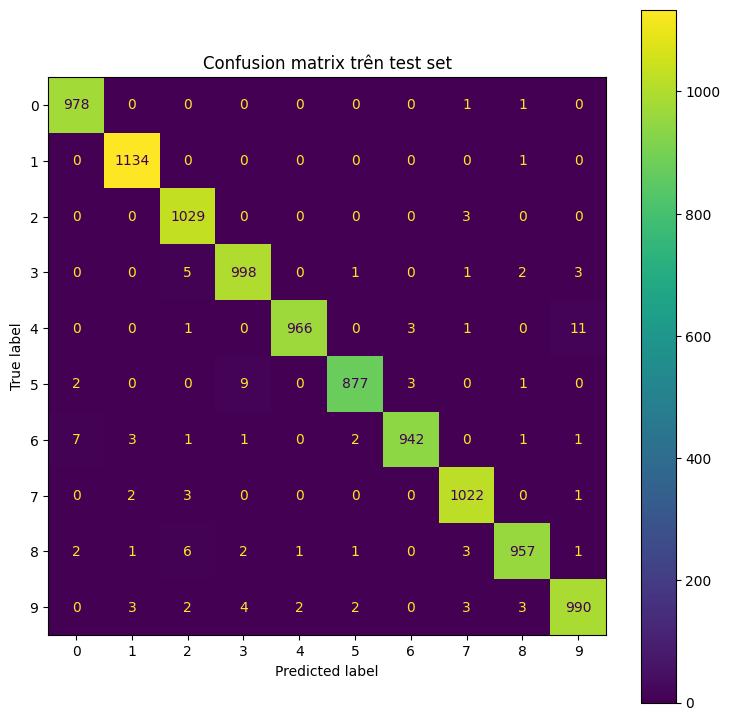

In [29]:
matrix = confusion_matrix(
    test_metrics["y_true"],
    test_metrics["y_pred"],
)

display = ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=list(range(10)),
)

fig, axis = plt.subplots(figsize=(9, 9))
display.plot(ax=axis, values_format="d")
axis.set_title("Confusion matrix trên test set")
plt.show()

## 26. Xem các ảnh dự đoán sai

Phân tích lỗi giúp hiểu mô hình đang gặp khó khăn với:

- Chữ viết quá mờ.
- Chữ số viết không chuẩn.
- Hai lớp có hình dạng gần nhau.
- Ảnh có nét bị đứt hoặc nghiêng.

In [30]:
def collect_misclassified_samples(model, dataloader, max_samples=12):
    model.eval()
    samples = []

    with torch.no_grad():
        for batch in dataloader:
            images = batch["image"].to(device)
            labels = batch["label"].to(device)

            logits = model(images)
            probabilities = torch.softmax(logits, dim=1)
            predictions = logits.argmax(dim=1)

            wrong_indices = (predictions != labels).nonzero(as_tuple=True)[0]

            for index in wrong_indices:
                samples.append(
                    {
                        "image": images[index].cpu(),
                        "true_label": labels[index].item(),
                        "predicted_label": predictions[index].item(),
                        "confidence": probabilities[index, predictions[index]].item(),
                    }
                )

                if len(samples) >= max_samples:
                    return samples

    return samples


misclassified_samples = collect_misclassified_samples(
    model,
    test_loader,
    max_samples=12,
)

print("Số ảnh sai được lấy để hiển thị:", len(misclassified_samples))

Số ảnh sai được lấy để hiển thị: 12


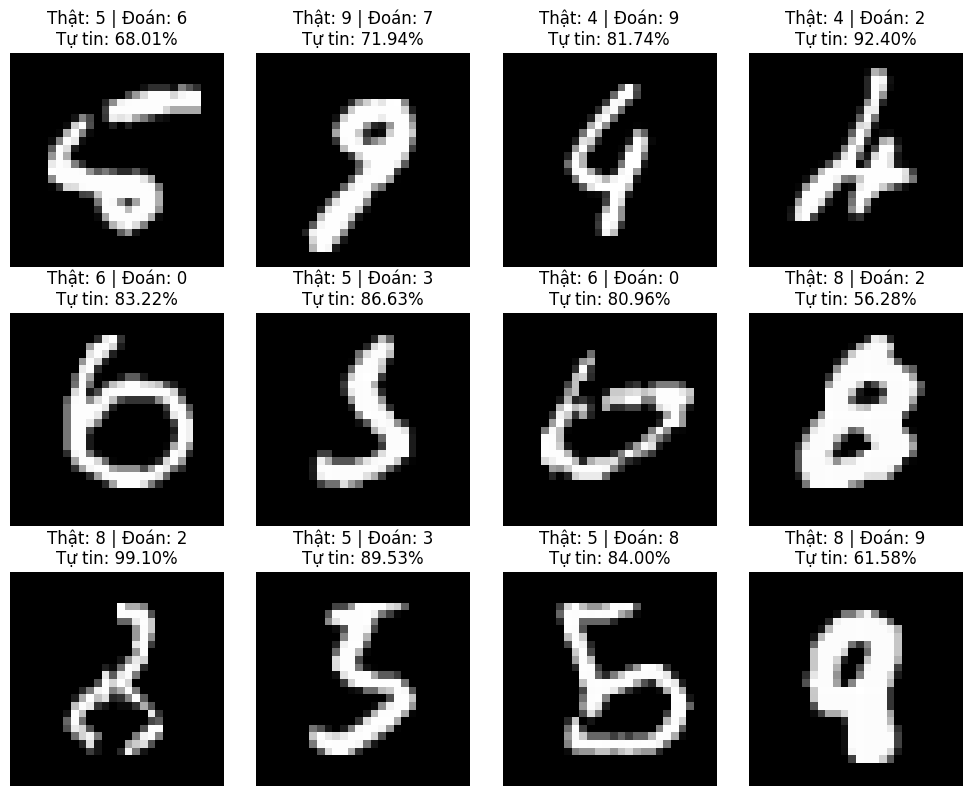

In [31]:
if misclassified_samples:
    fig, axes = plt.subplots(3, 4, figsize=(10, 8))

    for axis, sample in zip(axes.flat, misclassified_samples):
        axis.imshow(sample["image"].squeeze(0), cmap="gray")
        axis.set_title(
            f"Thật: {sample['true_label']} | "
            f"Đoán: {sample['predicted_label']}\n"
            f"Tự tin: {sample['confidence']:.2%}"
        )
        axis.axis("off")

    for axis in axes.flat[len(misclassified_samples):]:
        axis.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("Không có ảnh dự đoán sai trong dữ liệu đã duyệt.")

## 27. Dự đoán một ảnh riêng lẻ

Softmax chỉ cần dùng khi muốn chuyển logits thành xác suất để diễn giải kết quả.

Trong quá trình huấn luyện, vẫn phải đưa logits trực tiếp vào `CrossEntropyLoss`.

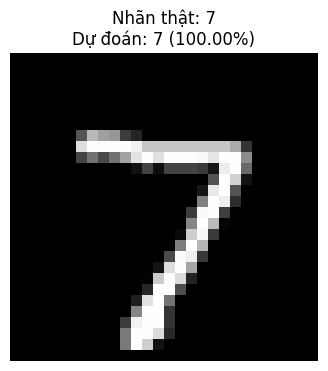

In [32]:
def predict_one(model, dataset, index):
    model.eval()

    sample = dataset[index]
    image = sample["image"].unsqueeze(0).to(device)

    with torch.no_grad():
        logits = model(image)
        probabilities = torch.softmax(logits, dim=1)
        predicted_label = probabilities.argmax(dim=1).item()
        confidence = probabilities[0, predicted_label].item()

    return {
        "image": sample["image"],
        "true_label": sample["label"].item(),
        "predicted_label": predicted_label,
        "confidence": confidence,
        "probabilities": probabilities.squeeze(0).cpu(),
    }


prediction = predict_one(
    model=model,
    dataset=test_dataset,
    index=0,
)

plt.figure(figsize=(4, 4))
plt.imshow(prediction["image"].squeeze(0), cmap="gray")
plt.title(
    f"Nhãn thật: {prediction['true_label']}\n"
    f"Dự đoán: {prediction['predicted_label']} "
    f"({prediction['confidence']:.2%})"
)
plt.axis("off")
plt.show()

# Phần F – Tổng kết kiến thức

## 28. Quy trình chuẩn của bài toán phân loại ảnh

```text
1. Kiểm tra dữ liệu
2. Chia train – validation – test
3. Tạo Dataset và DataLoader
4. Xây dựng mô hình
5. Sanity check kích thước đầu ra
6. Chọn loss và optimizer
7. Huấn luyện trên train set
8. Theo dõi validation set
9. Lưu checkpoint tốt nhất
10. Tải lại checkpoint tốt nhất
11. Đánh giá test đúng một lần
12. Phân tích confusion matrix và ảnh dự đoán sai
```

## 29. Các lỗi sinh viên thường gặp

### Lỗi 1: Dùng test set sau mỗi epoch

Sai vì test set đã tham gia gián tiếp vào lựa chọn mô hình.

### Lỗi 2: Thêm Softmax trước CrossEntropyLoss

Không cần thiết và có thể làm việc tính toán kém ổn định hơn.

### Lỗi 3: Quên `optimizer.zero_grad()`

Gradient bị cộng dồn giữa các batch.

### Lỗi 4: Quên `model.eval()` khi đánh giá

Một số lớp như Dropout và BatchNorm sẽ hoạt động không đúng chế độ đánh giá.

### Lỗi 5: Quên `torch.no_grad()`

Chương trình lưu graph không cần thiết, gây tốn bộ nhớ.

### Lỗi 6: Chỉ lưu mô hình nhưng không tải lại

Mô hình ở epoch cuối chưa chắc là mô hình tốt nhất.

### Lỗi 7: Không đặt random seed

Kết quả khó tái lập và khó so sánh công bằng.

### Lỗi 8: Nộp notebook chưa chạy

Giảng viên không thể kiểm tra loss, accuracy, biểu đồ và lỗi runtime thực tế.

# Phần G – Câu hỏi tự kiểm tra

1. Vì sao không được dùng test set để chọn checkpoint?
2. `model.train()` và `model.eval()` khác nhau như thế nào?
3. Vì sao không đặt Softmax trong `forward()`?
4. Tensor đầu vào của `Conv2d` có thứ tự các chiều như thế nào?
5. Sau `Conv2` trong mô hình này, feature map có kích thước bao nhiêu?
6. Macro F1 khác accuracy ở điểm nào?
7. Vì sao phải tải lại checkpoint tốt nhất trước khi test?
8. Dấu hiệu nào trên biểu đồ cho thấy mô hình có thể bị overfitting?

# Phần H – Bài tập mở rộng

## Bài 1: So sánh pooling

Thay `AvgPool2d` bằng `MaxPool2d`.  
Giữ nguyên các yếu tố khác và so sánh validation macro F1.

## Bài 2: So sánh optimizer

Thử:

- Adam với learning rate 0.001.
- SGD với momentum 0.9.

Không được dùng test set để chọn optimizer.

## Bài 3: Thêm Dropout

Thêm Dropout sau lớp Linear 120 → 84.  
Quan sát train loss và validation loss.

## Bài 4: Chuẩn hóa dữ liệu

Tính mean và standard deviation chỉ từ train set, sau đó chuẩn hóa ảnh.  
So sánh tốc độ hội tụ.

## Bài 5: Phân tích lớp khó nhất

Từ classification report và confusion matrix:

- Xác định lớp có F1 thấp nhất.
- Tìm lớp mà nó thường bị nhầm thành.
- Hiển thị ít nhất 10 ảnh minh họa.

## Bài 6: Báo cáo thí nghiệm

Viết báo cáo ngắn gồm:

1. Cấu hình thí nghiệm.
2. Kiến trúc mô hình.
3. Biểu đồ huấn luyện.
4. Kết quả validation tốt nhất.
5. Kết quả test cuối cùng.
6. Confusion matrix.
7. Nhận xét về các lỗi dự đoán.

# Checklist trước khi nộp bài

- [ ] Notebook chạy từ đầu đến cuối bằng `Restart & Run All`.
- [ ] Không có ô code báo lỗi.
- [ ] Có đầy đủ output huấn luyện.
- [ ] Có biểu đồ train và validation.
- [ ] Có kết quả test cuối cùng.
- [ ] Có classification report.
- [ ] Có confusion matrix.
- [ ] Có ảnh dự đoán sai.
- [ ] Không dùng test set để lựa chọn mô hình.
- [ ] Đã lưu notebook sau khi chạy xong.